In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

In [3]:
class clickGenerator:

    def __init__(self, ctr):
        self.ctr = ctr
        #self.click_sample_size = click_sample_size

    # click binomial function generator

    def generateClicks(self, click_sample_size):
        return np.random.binomial(n=1, p=self.ctr, size=click_sample_size)

In [4]:
control_version = clickGenerator(0.05)
treatment_version = clickGenerator(0.0525)

In [5]:
class SPRT_GST:

    def __init__(self,total_sample_size, dump_size, baseline_ctr, mde, test_version ):
        self.total_sample_size = total_sample_size
        self.dump_size = dump_size
        self.baseline_ctr = baseline_ctr
        self.mde = mde
        self.test_version = test_version

    @staticmethod
    def boundry_thresholds(alpha, beta):
        
        a = np.log( beta / (1-alpha) )
        b = np.log( (1-beta) / alpha )

        return np.round((a, b),4)
    
     
    def log_liklihood_ratio_binomial_func(self, baseline_ctr, mde, clicks, non_clicks):
        
        p1 = baseline_ctr + mde
        p0 = baseline_ctr

        part1 = clicks * np.log(p1/p0)
        part2 = non_clicks * np.log((1-p1)/(1-p0))

        log_delta = part1 + part2

        return log_delta

    def SPRT_Test(self, upper_boundry, lower_boundry):
         
         total_steps = int(self.total_sample_size/ self.dump_size)
         observed_data_logs = np.array([])
         sample_size = 0
         lambda_logs = np.zeros(total_steps)
         sample_size_bag = np.zeros(total_steps)
         

         for i in range(total_steps):
             
             sample_data = self.test_version.generateClicks(self.dump_size)
             sample_size = sample_size  +  self.dump_size 
             observed_data_logs = np.concatenate((observed_data_logs, sample_data))
             clicks = observed_data_logs.sum()
             non_clicks = len(observed_data_logs) - clicks

             lambda_ = self.log_liklihood_ratio_binomial_func(baseline_ctr=self.baseline_ctr,
                                                         mde=self.mde,
                                                         clicks=clicks,
                                                         non_clicks=non_clicks)
             #print(lambda_)
             sample_size_bag[i] = sample_size 
             lambda_logs[i] = lambda_
             #print(len(observed_data_logs))
        
             if lambda_ >= upper_boundry:
                  #print("Accept Alternative Hypothesis")
                  break
             elif lambda_ <= lower_boundry:
                  #print("Accept Null Hypothesis")
                  break
             else:
                 continue
    
         #print(lambda_logs)
         lambda_logs = lambda_logs[lambda_logs != 0]
         sample_size_bag = sample_size_bag[sample_size_bag !=0]
         used_sample_size = len(observed_data_logs)
         #print(lambda_logs)

         return lambda_logs, used_sample_size, sample_size_bag

    def sprt_simulation(self, simulation_trials, upper_boundry, lower_boundry):
        
        p_hits_b = 0
        p_hits_a = 0
        sample_size = 0
        for i in range(simulation_trials):
            
            lambda_logs, used_sample_size, _ =  self.SPRT_Test(upper_boundry,lower_boundry)
            critical_value = lambda_logs[-1]
            #print(critical_value)
            sample_size = sample_size + used_sample_size

            if critical_value >= b:
                p_hits_b = p_hits_b + 1
                #print(f"p_hits_b {p_hits_b}")
        
            if critical_value <=a:
                p_hits_a = p_hits_a + 1
                #print(f"p_hits_a {p_hits_a}")

        #print(p_hits_b, p_hits_a)
        fpr_rate = np.round(1 - (p_hits_a/simulation_trials),3)
        power_rate = np.round((p_hits_b/simulation_trials),3)
        average_sample_size = np.round((sample_size/simulation_trials),3)
        #print(fpr_rate, power_rate)
        return fpr_rate, power_rate, average_sample_size
    
    

In [6]:
total_sample_size = 120000
dump_size = 1000
baseline_ctr = 0.05
mde = 0.0025


aatest_sprt = SPRT_GST(total_sample_size=total_sample_size,
                        dump_size =dump_size,
                        baseline_ctr = baseline_ctr,
                        mde = mde,
                        test_version=control_version)

abtest_sprt = SPRT_GST(total_sample_size=total_sample_size,
                        dump_size =dump_size,
                        baseline_ctr = baseline_ctr,
                        mde = mde,
                        test_version=treatment_version)

In [7]:
def sprt_test_plot(sprt_test, upper_boundry, lower_boundry):
    lambda_logs, used_sample_size, sample_size_bag = sprt_test.SPRT_Test(upper_boundry,lower_boundry)
    fig, axs = plt.subplots(figsize=(10, 2.5))
    sns.lineplot(x=sample_size_bag, y=lambda_logs, color="mediumpurple",linewidth=2.5, alpha=1.0, ax=axs)
    axs.axhline(b, color="k", linestyle="--", label=b)
    axs.axhline(a, color="k", linestyle="--", label=a)
    axs.set_xlim(0, total_sample_size)
    axs.set_ylim(-5.5,5.5)
    axs.set(ylabel="sprt-score")
    axs.set_title("SPRT Cumulative Score", weight=None)
    axs.legend();

    return fig

In [8]:
# boundry threshold calculation 
alpha_significance_level =  0.05
beta = 0.20

a, b = aatest_sprt.boundry_thresholds(alpha=0.05, beta=0.20)
a = np.round(a, 3)
b = np.round(b, 3)

print(f"Critical Upper Boundry Threshold : {b}")
print(f"Critical Lower Boundry Threshold : {a}")

Critical Upper Boundry Threshold : 2.773
Critical Lower Boundry Threshold : -1.558


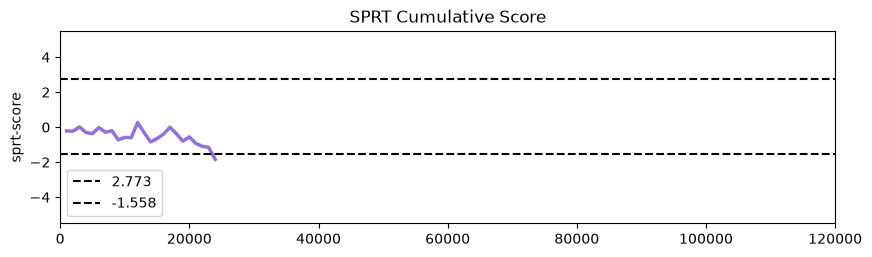

In [9]:
_ = sprt_test_plot(sprt_test = aatest_sprt, 
               upper_boundry = b,
               lower_boundry= a) 

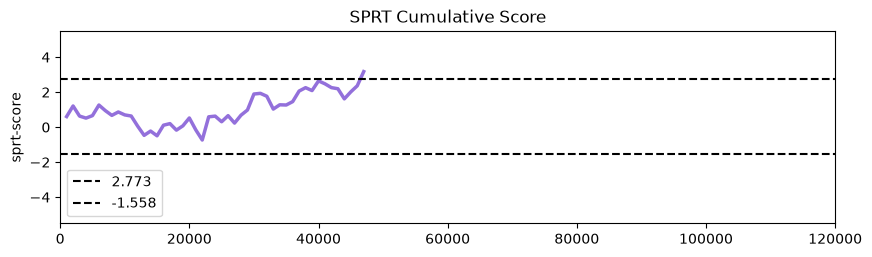

In [10]:
_ = sprt_test_plot(sprt_test = abtest_sprt, 
                   upper_boundry = b,
                   lower_boundry= a) 

In [11]:

def sprt_analysis(sprt_test, trials, simulation_trials, upper_boundry, lower_boundry, analysis_type):
    
    for i in range(trials):
        fpr_rate, power_rate, average_sample_size = sprt_test.sprt_simulation(simulation_trials,
                                                                                upper_boundry, 
                                                                                lower_boundry)
        if analysis_type == "fpr": 
            print(f"Trial {i} | FPR Rate {fpr_rate} | Average Sample Size {average_sample_size}")
        if analysis_type == "power": 
            print(f"Trial {i} | Power Rate {power_rate} | Average Sample Size {average_sample_size}")
        

In [12]:
simulation_trials = 1000
trials = 10

sprt_analysis(sprt_test=aatest_sprt, 
              trials=trials,
              simulation_trials=simulation_trials,
              upper_boundry=b,
              lower_boundry=a,
              analysis_type="fpr")

Trial 0 | FPR Rate 0.045 | Average Sample Size 25074.0
Trial 1 | FPR Rate 0.047 | Average Sample Size 23837.0
Trial 2 | FPR Rate 0.04 | Average Sample Size 24758.0
Trial 3 | FPR Rate 0.045 | Average Sample Size 24223.0
Trial 4 | FPR Rate 0.044 | Average Sample Size 24800.0
Trial 5 | FPR Rate 0.059 | Average Sample Size 24968.0
Trial 6 | FPR Rate 0.059 | Average Sample Size 23972.0
Trial 7 | FPR Rate 0.042 | Average Sample Size 24610.0
Trial 8 | FPR Rate 0.06 | Average Sample Size 26115.0
Trial 9 | FPR Rate 0.042 | Average Sample Size 25085.0


In [13]:
simulation_trials = 1000
trials = 10

sprt_analysis(sprt_test=abtest_sprt, 
              trials=trials,
              simulation_trials=simulation_trials,
              upper_boundry=b,
              lower_boundry=a,
              analysis_type="power")

Trial 0 | Power Rate 0.814 | Average Sample Size 33905.0
Trial 1 | Power Rate 0.8 | Average Sample Size 33905.0
Trial 2 | Power Rate 0.798 | Average Sample Size 34510.0
Trial 3 | Power Rate 0.812 | Average Sample Size 32612.0
Trial 4 | Power Rate 0.83 | Average Sample Size 34290.0
Trial 5 | Power Rate 0.842 | Average Sample Size 33526.0
Trial 6 | Power Rate 0.829 | Average Sample Size 33204.0
Trial 7 | Power Rate 0.795 | Average Sample Size 32194.0
Trial 8 | Power Rate 0.816 | Average Sample Size 34475.0
Trial 9 | Power Rate 0.826 | Average Sample Size 33927.0
